# 03 · Evaluación operativa retrospectiva

**Pregunta:** si el modelo hubiera estado desplegado en los datos disponibles, ¿cuántos picos habría detectado, con cuánta anticipación y a costa de cuántas falsas alarmas?

Esta libreta no entrena un modelo nuevo: usa **predicciones out-of-fold** del modelo de la libreta 02 y evalúa el sistema de alertas a nivel de **episodio de pico**, no de minuto. Es la evaluación que reemplaza al piloto que no se puede hacer.

**Entradas:** `data/processed/medidor200_1min.csv`.
**Salidas:** tablas y figuras en `reports/`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pd.set_option("display.width", 180)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path(".").resolve()
DATA = ROOT / "data" / "processed" / "medidor200_1min.csv"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)
assert DATA.exists(), "Corré 01_data_audit.ipynb primero."

d = pd.read_csv(DATA, parse_dates=["ts_utc"], index_col="ts_utc")
d.index = pd.to_datetime(d.index, utc=True)
print(d.shape)

(66767, 11)


## 1. Features y target

Se replican exactamente las features de la libreta 02: `P_max15`, `P_mean15`, `V`, `PF`, hora (seno/coseno) y fin de semana. El target es $Y_t=\mathbf{1}\{\max_{1\le h\le 15}P_{t+h}>12\}$.

In [2]:
d["P_max15"] = d["P"].rolling(15, min_periods=8).max()
d["P_mean15"] = d["P"].rolling(15, min_periods=8).mean()
loc = d.index.tz_convert("America/Bogota")
d["hour"] = loc.hour
d["is_weekend"] = (loc.dayofweek >= 5).astype(int)
d["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
d["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)

H, P_THR = 15, 12.0
future_max = d["P"].rolling(H, min_periods=H).max().shift(-H)
d["Y"] = (future_max > P_THR).astype(float)
d.loc[future_max.isna(), "Y"] = np.nan

features = ["P_max15", "P_mean15", "V", "PF", "hour_sin", "hour_cos", "is_weekend"]
data = d.dropna(subset=features + ["Y"]).copy()
print(f"Filas: {len(data):,} | positivos: {int(data.Y.sum()):,} | tasa base: {data.Y.mean():.4f}")

Filas: 35,375 | positivos: 948 | tasa base: 0.0268


## 2. Predicciones out-of-fold

Para evaluar sin fuga, cada bloque de días se predice con un modelo entrenado **solo con los bloques anteriores**:

$$
\hat p_t^{\text{oof}} = f_{\hat\theta^{(-k(t))}}(x_t),
$$

donde $k(t)$ es el bloque de días al que pertenece $t$ y $\hat\theta^{(-k)}$ se entrena con los bloques $1,\dots,k-1$. El primer bloque no tiene historia previa y se excluye de la evaluación.

In [3]:
def make_logit():
    return Pipeline([("sc", StandardScaler()),
                     ("lr", LogisticRegression(C=1.0, max_iter=5000))])

days = np.array(sorted(set(data.index.tz_convert("America/Bogota").date)))
blocks = np.array_split(days, 6)
oof = data.copy()
oof["p_oof"] = np.nan

for k in range(1, 6):
    tr_days = set().union(*blocks[:k])
    te_days = set(blocks[k])
    tr = data[np.isin(data.index.tz_convert("America/Bogota").date, list(tr_days))]
    te = data[np.isin(data.index.tz_convert("America/Bogota").date, list(te_days))]
    m = make_logit().fit(tr[features], tr["Y"])
    oof.loc[te.index, "p_oof"] = m.predict_proba(te[features])[:, 1]

oof = oof.dropna(subset=["p_oof"]).copy()
N_DAYS = len(set(oof.index.tz_convert("America/Bogota").date))
print(f"OOF: {len(oof):,} filas | {N_DAYS} días | {oof.index.min()} -> {oof.index.max()}")
print(oof.groupby(oof.index.tz_convert("America/Bogota").date)["p_oof"].agg(["count", "max"]).tail(8).round(3).to_string())

OOF: 29,550 filas | 26 días | 2026-10-19 05:00:00+00:00 -> 2026-11-21 22:37:00+00:00
            count    max
2026-11-08   1425  0.000
2026-11-13    830  0.531
2026-11-14   1440  0.002
2026-11-15   1440  0.000
2026-11-16   1440  0.002
2026-11-17   1246  0.592
2026-11-18    786  0.501
2026-11-21   1034  0.001


## 3. Definición de episodios

**Episodio de pico.** Un pico no es un minuto: es un intervalo. Se define como una corrida maximal de minutos con $P_t>12$, cerrando huecos internos de hasta 5 min para no partir un mismo evento:

$$
\mathcal{P}=\{[s_j,e_j]\}_{j=1}^{N_P}.
$$

**Episodio de alerta.** Una corrida maximal de minutos con $\hat p_t\ge\tau$, con un *cooldown* de 15 min para no contar la misma alerta varias veces:

$$
\mathcal{A}=\{[a_i,b_i]\}_{i=1}^{N_A}.
$$

**Detección.** El pico $j$ se detecta si hay al menos una alerta en los $H=15$ min previos a su inicio:

$$
D_j=\mathbf{1}\left\{\exists\, a_i\in\mathcal{A}:\; s_j-H\le a_i<s_j\right\}.
$$

**Anticipación (lead time):**

$$
L_j=s_j-\min\{a_i:\; s_j-H\le a_i<s_j\}.
$$

In [4]:
def peak_episodes(P, thr=12.0, merge_gap=5, min_len=1):
    mask = (P > thr).fillna(False).to_numpy()
    idx = P.index
    n = len(mask)
    closed = mask.copy()
    i = 0
    while i < n:
        if not mask[i]:
            j = i
            while j < n and not mask[j]:
                j += 1
            if i > 0 and j < n and mask[i - 1] and mask[j] and (j - i) <= merge_gap:
                closed[i:j] = True
            i = j
        else:
            i += 1
    eps = []
    i = 0
    while i < n:
        if closed[i]:
            j = i
            while j < n and closed[j]:
                j += 1
            if (j - i) >= min_len:
                eps.append((idx[i], idx[j - 1]))
            i = j
        else:
            i += 1
    return eps


def alert_episodes(score, thr, cooldown=15):
    mask = (score >= thr).fillna(False).to_numpy()
    idx = score.index
    n = len(mask)
    eps = []
    i = 0
    while i < n:
        if mask[i]:
            j = i
            while j < n and mask[j]:
                j += 1
            eps.append((idx[i], idx[j - 1]))
            i = j + cooldown
        else:
            i += 1
    return eps

peaks = peak_episodes(oof["P"], P_THR, merge_gap=5)
print("Episodios de pico:", len(peaks))
print("Primeros 5:", [(str(s), str(e)) for s, e in peaks[:5]])

Episodios de pico: 58
Primeros 5: [('2026-10-19 15:10:00+00:00', '2026-10-19 15:11:00+00:00'), ('2026-10-19 15:57:00+00:00', '2026-10-19 16:02:00+00:00'), ('2026-10-19 16:19:00+00:00', '2026-10-19 16:23:00+00:00'), ('2026-10-19 16:32:00+00:00', '2026-10-19 16:32:00+00:00'), ('2026-10-19 16:56:00+00:00', '2026-10-19 16:56:00+00:00')]


## 4. Métricas a nivel de evento

**Recall de picos:**

$$
R(\tau)=\frac{1}{N_P}\sum_{j=1}^{N_P}D_j(\tau).
$$

**Precisión de alertas:** una alerta es TP si cae en la ventana previa de algún pico; si no, es FP.

$$
P(\tau)=\frac{TP(\tau)}{TP(\tau)+FP(\tau)}.
$$

**Falsas alarmas por día:**

$$
\mathrm{FA/d}(\tau)=\frac{FP(\tau)}{N_d}.
$$

**Costo operativo** con $C_{FP}$ por falsa alarma y $C_{FN}$ por pico perdido:

$$
C(\tau)=C_{FP}\,FP(\tau)+C_{FN}\,(N_P-TP_{\text{picos}}(\tau))+\frac{C_{FP}}{60}\,A(\tau),
$$

donde $A(\tau)$ es la cantidad de minutos en alerta. El término $C_{FP}/60$ equivale a castigar una hora de alerta como una falsa alarma; sin él, un sistema que alerta todo el tiempo tendría costo cero en falsos positivos. El umbral óptimo es $\tau^*=\arg\min_\tau C(\tau)$. En la práctica se barre $\tau$ sobre los cuantiles del score.

In [5]:
def evaluate(score, P_series, peaks, thr, H=15, cooldown=15):
    alerts = alert_episodes(score, thr, cooldown)
    tp_alerts = set()
    peak_rows = []
    for j, (s, e) in enumerate(peaks):
        ws = s - pd.Timedelta(minutes=H)
        cand = [(a, b) for a, b in alerts if a < s and b >= ws]
        detected = len(cand) > 0
        first = min(max(a, ws) for a, b in cand) if cand else pd.NaT
        first_start = min(a for a, b in cand) if cand else pd.NaT
        lead = (s - first).total_seconds() / 60 if detected else np.nan
        peak_rows.append({
            "peak_id": j, "start": s, "end": e,
            "duration_min": (e - s).total_seconds() / 60 + 1,
            "max_P": P_series.loc[s:e].max(),
            "detected": detected, "first_alert": first,
            "alert_start": first_start, "lead_min": lead,
        })
        for ab in cand:
            tp_alerts.add(ab)

    alert_rows = []
    for i, (a, b) in enumerate(alerts):
        alert_rows.append({
            "alert_id": i, "start": a, "end": b,
            "type": "TP" if (a, b) in tp_alerts else "FP",
        })

    tp = len(tp_alerts)
    fp = len(alerts) - tp
    n_det = sum(r["detected"] for r in peak_rows)
    leads = [r["lead_min"] for r in peak_rows if r["detected"]]
    return {
        "threshold": thr,
        "n_alerts": len(alerts), "tp_alerts": tp, "fp_alerts": fp,
        "n_peaks": len(peaks), "detected": n_det,
        "recall": n_det / len(peaks) if peaks else np.nan,
        "precision": tp / len(alerts) if alerts else np.nan,
        "fa_per_day": fp / N_DAYS,
        "alert_burden": float((score >= thr).mean()),
        "alert_minutes": float((score >= thr).sum()),
        "lead_median": float(np.median(leads)) if leads else np.nan,
        "lead_p25": float(np.percentile(leads, 25)) if leads else np.nan,
        "lead_p75": float(np.percentile(leads, 75)) if leads else np.nan,
    }, peak_rows, alert_rows

print("Peaks:", len(peaks))

Peaks: 58


## 5. Barrido de umbral: modelo vs persistencia

Se barre el umbral sobre los cuantiles del score, para comparar ambos sistemas a **igual carga de alertas**. La persistencia usa $P_t$ como score; el modelo usa $\hat p_t^{\text{oof}}$.

In [6]:
qs = np.linspace(0.5, 0.999, 30)
model_ths = np.unique(np.quantile(oof["p_oof"], qs))
pers_ths = np.unique(np.quantile(oof["P"], qs))

rows = []
for th in model_ths:
    m, _, _ = evaluate(oof["p_oof"], oof["P"], peaks, th)
    rows.append({"score": "modelo", **m})
for th in pers_ths:
    m, _, _ = evaluate(oof["P"], oof["P"], peaks, th)
    rows.append({"score": "persistencia", **m})

metrics = pd.DataFrame(rows)
display(metrics.groupby("score")[["recall", "precision", "fa_per_day", "alert_burden", "lead_median"]].max().round(3))
display(metrics.sort_values(["score", "alert_burden"]).head(8).round(3))

,recall,precision,fa_per_day,alert_burden,lead_median
score,,,,,
modelo,1.0,0.375,4.346,0.5,15.0
persistencia,1.0,0.210,25.885,0.5,15.0


,score,threshold,n_alerts,tp_alerts,fp_alerts,n_peaks,detected,recall,precision,fa_per_day,alert_burden,alert_minutes,lead_median,lead_p25,lead_p75
29,modelo,0.936,1,0,1,58,0,0.000,0.000,0.038,0.001,30.0,NaN,NaN,NaN
28,modelo,0.350,48,18,30,58,23,0.397,0.375,1.154,0.018,538.0,15.0,8.5,15.0
27,modelo,0.219,72,19,53,58,32,0.552,0.264,2.038,0.035,1047.0,15.0,8.0,15.0
26,modelo,0.140,77,21,56,58,37,0.638,0.273,2.154,0.053,1555.0,15.0,8.0,15.0
25,modelo,0.087,78,26,52,58,46,0.793,0.333,2.000,0.070,2064.0,15.0,8.0,15.0
24,modelo,0.056,81,25,56,58,47,0.810,0.309,2.154,0.087,2572.0,15.0,12.5,15.0
23,modelo,0.035,89,25,64,58,49,0.845,0.281,2.462,0.104,3081.0,15.0,13.0,15.0
22,modelo,0.023,91,26,65,58,53,0.914,0.286,2.500,0.121,3589.0,15.0,14.0,15.0


## 6. Costo y umbral elegido

Se evalúa el costo para distintas razones $C_{FN}/C_{FP}$. Un pico perdido puede costar 10, 20 o 50 falsas alarmas; el umbral óptimo cambia con esa razón.

In [7]:
cost_rows = []
for ratio in [1, 5, 10, 20, 50]:
    for _, r in metrics.iterrows():
        missed = r["n_peaks"] - r["detected"]
        cost = r["fp_alerts"] + ratio * missed + r["alert_minutes"] / 60
        cost_rows.append({"score": r["score"], "ratio": ratio,
                          "threshold": r["threshold"],
                          "cost_per_peak": cost / r["n_peaks"],
                          "recall": r["recall"], "precision": r["precision"],
                          "fa_per_day": r["fa_per_day"],
                          "alert_burden": r["alert_burden"]})
cost = pd.DataFrame(cost_rows)

best = (cost[cost.score == "modelo"]
        .sort_values(["ratio", "cost_per_peak"])
        .groupby("ratio").first().reset_index())
display(best.round(3))

ratio = 10
row = best[best.ratio == ratio].iloc[0]
tau = float(row["threshold"])
m_star, peak_rows, alert_rows = evaluate(oof["p_oof"], oof["P"], peaks, tau)
print(f"Umbral elegido (ratio {ratio}): {tau:.4f}")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in m_star.items()})

# Puntos de operación a igual carga de alertas: modelo vs persistencia
ops = []
for target in [0.02, 0.05, 0.10, 0.20]:
    gm = metrics[metrics.score == "modelo"]
    gp = metrics[metrics.score == "persistencia"]
    rm = gm.iloc[(gm.alert_burden - target).abs().argsort()[:1]].iloc[0]
    rp = gp.iloc[(gp.alert_burden - target).abs().argsort()[:1]].iloc[0]
    ops.append({
        "carga_objetivo": target,
        "modelo_carga": rm.alert_burden, "modelo_recall": rm.recall,
        "modelo_precision": rm.precision, "modelo_fa_dia": rm.fa_per_day,
        "pers_carga": rp.alert_burden, "pers_recall": rp.recall,
        "pers_precision": rp.precision, "pers_fa_dia": rp.fa_per_day,
    })
ops = pd.DataFrame(ops)
display(ops.round(3))

# Punto operativo al 5 % de carga de alertas: se usa para el análisis de errores
gm = metrics[metrics.score == "modelo"]
row_op = gm.iloc[(gm.alert_burden - 0.05).abs().argsort()[:1]].iloc[0]
tau_op = float(row_op["threshold"])
m_op, peak_rows_op, alert_rows_op = evaluate(oof["p_oof"], oof["P"], peaks, tau_op)
print(f"Punto operativo (5% de carga): umbral {tau_op:.4f}")
print({k: round(v, 3) if isinstance(v, float) else v for k, v in m_op.items()})

,ratio,score,threshold,cost_per_peak,recall,precision,fa_per_day,alert_burden
0,1,modelo,0.936,1.026,0.000,0.000,0.038,0.001
1,5,modelo,0.087,2.524,0.793,0.333,2.000,0.070
2,10,modelo,0.002,2.547,1.000,0.260,2.077,0.190
3,20,modelo,0.002,2.547,1.000,0.260,2.077,0.190
4,50,modelo,0.002,2.547,1.000,0.260,2.077,0.190


Umbral elegido (ratio 10): 0.0019
{'threshold': 0.002, 'n_alerts': 73, 'tp_alerts': 19, 'fp_alerts': 54, 'n_peaks': 58, 'detected': 58, 'recall': 1.0, 'precision': 0.26, 'fa_per_day': 2.077, 'alert_burden': 0.19, 'alert_minutes': 5623.0, 'lead_median': 15.0, 'lead_p25': 15.0, 'lead_p75': 15.0}


,carga_objetivo,modelo_carga,modelo_recall,modelo_precision,modelo_fa_dia,pers_carga,pers_recall,pers_precision,pers_fa_dia
0,0.02,0.018,0.397,0.375,1.154,0.018,0.638,0.210,4.923
1,0.05,0.053,0.638,0.273,2.154,0.053,0.879,0.152,9.038
2,0.10,0.104,0.845,0.281,2.462,0.104,0.948,0.119,10.538
3,0.20,0.207,1.000,0.228,2.346,0.207,1.000,0.102,8.808


Punto operativo (5% de carga): umbral 0.1397
{'threshold': 0.14, 'n_alerts': 77, 'tp_alerts': 21, 'fp_alerts': 56, 'n_peaks': 58, 'detected': 37, 'recall': 0.638, 'precision': 0.273, 'fa_per_day': 2.154, 'alert_burden': 0.053, 'alert_minutes': 1555.0, 'lead_median': 15.0, 'lead_p25': 8.0, 'lead_p75': 15.0}


## 7. Figuras del trade-off

- Recall, precisión y falsas alarmas por día contra la carga de alertas.
- Costo por pico contra la carga de alertas, para el modelo y la persistencia.
- Distribución del lead time.

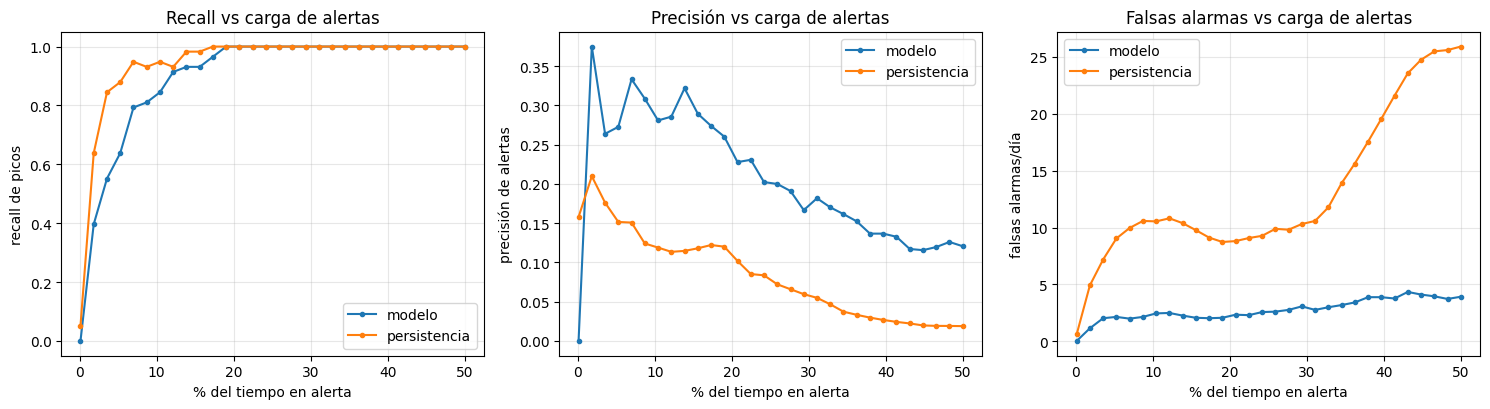

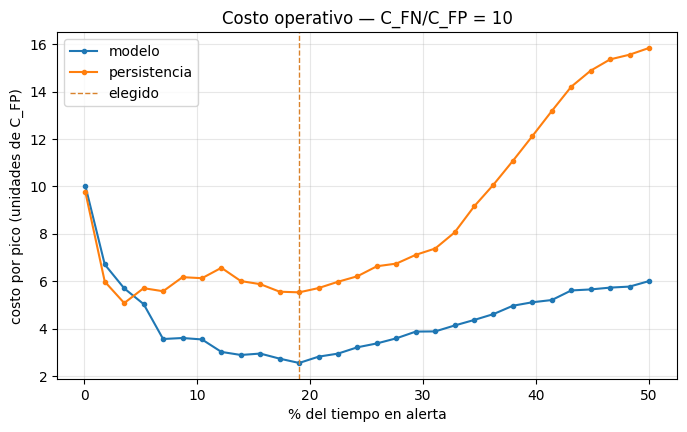

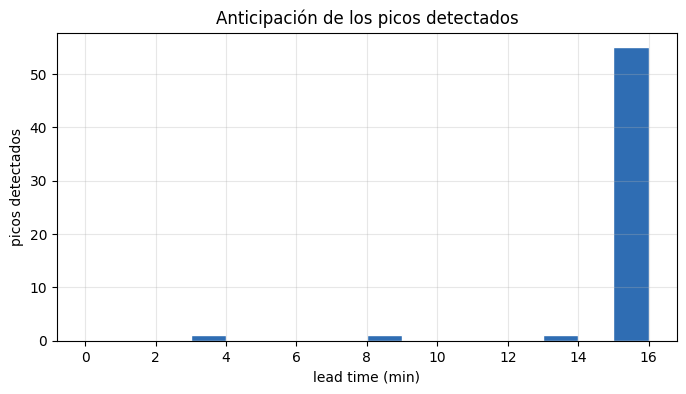

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for score, g in metrics.groupby("score"):
    g = g.sort_values("alert_burden")
    axes[0].plot(g.alert_burden * 100, g.recall, "o-", ms=3, label=score)
    axes[1].plot(g.alert_burden * 100, g.precision, "o-", ms=3, label=score)
    axes[2].plot(g.alert_burden * 100, g.fa_per_day, "o-", ms=3, label=score)
axes[0].set_xlabel("% del tiempo en alerta"); axes[0].set_ylabel("recall de picos")
axes[0].set_title("Recall vs carga de alertas"); axes[0].legend()
axes[1].set_xlabel("% del tiempo en alerta"); axes[1].set_ylabel("precisión de alertas")
axes[1].set_title("Precisión vs carga de alertas"); axes[1].legend()
axes[2].set_xlabel("% del tiempo en alerta"); axes[2].set_ylabel("falsas alarmas/día")
axes[2].set_title("Falsas alarmas vs carga de alertas"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIG / "03_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for score, g in cost[cost.ratio == ratio].groupby("score"):
    g = g.sort_values("alert_burden")
    ax.plot(g.alert_burden * 100, g.cost_per_peak, "o-", ms=3, label=score)
ax.axvline(m_star["alert_burden"] * 100, color="#d9822b", ls="--", lw=1, label="elegido")
ax.set_xlabel("% del tiempo en alerta"); ax.set_ylabel("costo por pico (unidades de C_FP)")
ax.set_title(f"Costo operativo — C_FN/C_FP = {ratio}"); ax.legend()
fig.savefig(FIG / "03_costos.png", dpi=150, bbox_inches="tight")
plt.show()

leads = [r["lead_min"] for r in peak_rows if r["detected"]]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(leads, bins=np.arange(0, 16.5, 1), color="#2f6db3", edgecolor="white")
ax.set_xlabel("lead time (min)"); ax.set_ylabel("picos detectados")
ax.set_title("Anticipación de los picos detectados")
fig.savefig(FIG / "03_lead_time.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Análisis de errores

Se perfila cada pico con su cobertura (`n` medio), hora y tipo de día. La pregunta es si el modelo falla donde los datos son peores (30 s, huecos) o donde el evento es intrínsecamente difícil.

,mean,count
coverage_group,,
10 s,0.769,13
30 s,0.600,45


,mean,count
is_weekend,,
False,0.638,58


,mean,count
hour,,
8,0.600,5
9,0.571,7
10,0.857,14
11,0.909,11
12,0.500,2
13,0.000,4
14,0.286,7
15,0.833,6
16,0.000,2


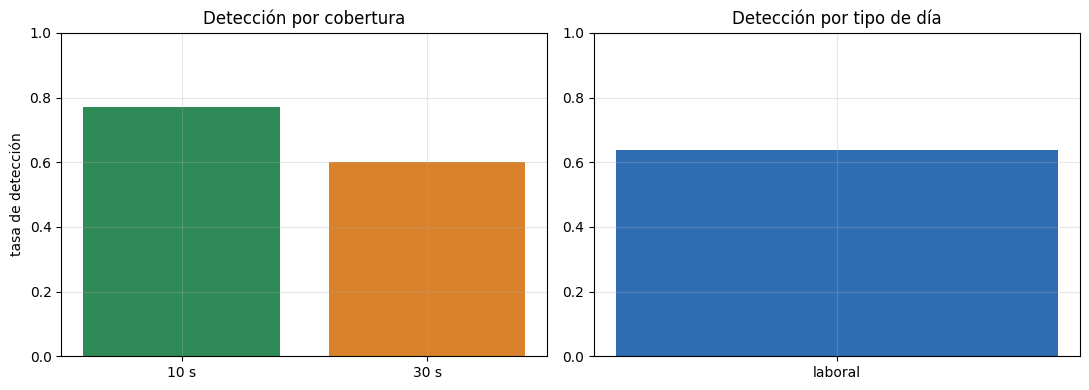

Picos perdidos:


C:\Users\Sebastian Tovar\AppData\Local\Temp\ipykernel_33964\1113914785.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .head(10)[["start", "end", "duration_min", "max_P", "n_mean", "hour", "is_weekend"]].round(2)


'                    start                       end  duration_min  max_P  n_mean  hour  is_weekend\n2026-10-27 13:35:00+00:00 2026-10-27 13:39:00+00:00           5.0  13.78    1.80     8       False\n2026-10-29 18:59:00+00:00 2026-10-29 18:59:00+00:00           1.0  13.23    2.00    13       False\n2026-10-26 14:07:00+00:00 2026-10-26 14:07:00+00:00           1.0  13.21    2.00     9       False\n2026-11-06 18:49:00+00:00 2026-11-06 18:49:00+00:00           1.0  12.98    2.00    13       False\n2026-10-26 19:55:00+00:00 2026-10-26 20:01:00+00:00           7.0  12.95    1.86    14       False\n2026-10-26 18:42:00+00:00 2026-10-26 18:42:00+00:00           1.0  12.91    1.00    13       False\n2026-11-03 19:18:00+00:00 2026-11-03 19:18:00+00:00           1.0  12.76    2.00    14       False\n2026-10-27 14:40:00+00:00 2026-10-27 14:47:00+00:00           8.0  12.71    1.88     9       False\n2026-11-04 21:09:00+00:00 2026-11-04 21:09:00+00:00           1.0  12.64    2.00    16       False\

In [9]:
peak_df = pd.DataFrame(peak_rows_op)
peak_df["n_mean"] = [oof.loc[s:e, "n"].mean() for s, e in zip(peak_df.start, peak_df.end)]
peak_df["hour"] = peak_df.start.dt.tz_convert("America/Bogota").dt.hour
peak_df["weekday"] = peak_df.start.dt.tz_convert("America/Bogota").dt.dayofweek
peak_df["is_weekend"] = peak_df.weekday >= 5
peak_df["coverage_group"] = np.where(peak_df.n_mean >= 5, "10 s", "30 s")

display(peak_df.groupby("coverage_group")["detected"].agg(["mean", "count"]).round(3))
display(peak_df.groupby("is_weekend")["detected"].agg(["mean", "count"]).round(3))
display(peak_df.groupby("hour")["detected"].agg(["mean", "count"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
g = peak_df.groupby("coverage_group")["detected"].mean()
axes[0].bar(g.index, g.values, color=["#2e8b57", "#d9822b"][:len(g)])
axes[0].set_ylim(0, 1); axes[0].set_title("Detección por cobertura")
axes[0].set_ylabel("tasa de detección")
g = peak_df.groupby("is_weekend")["detected"].mean()
axes[1].bar(["laboral", "fin de semana"][:len(g)], g.values, color=["#2f6db3", "#6a4c93"][:len(g)])
axes[1].set_ylim(0, 1); axes[1].set_title("Detección por tipo de día")
fig.tight_layout(); fig.savefig(FIG / "03_error_cobertura.png", dpi=150, bbox_inches="tight")
plt.show()

print("Picos perdidos:")
display(peak_df[~peak_df.detected].sort_values("max_P", ascending=False)
        .head(10)[["start", "end", "duration_min", "max_P", "n_mean", "hour", "is_weekend"]].round(2)
        .to_string(index=False))

## 9. Casos de estudio

Tres ventanas: un pico detectado, un pico perdido y una falsa alarma. Es la forma más honesta de mostrar qué hace el sistema en la práctica.

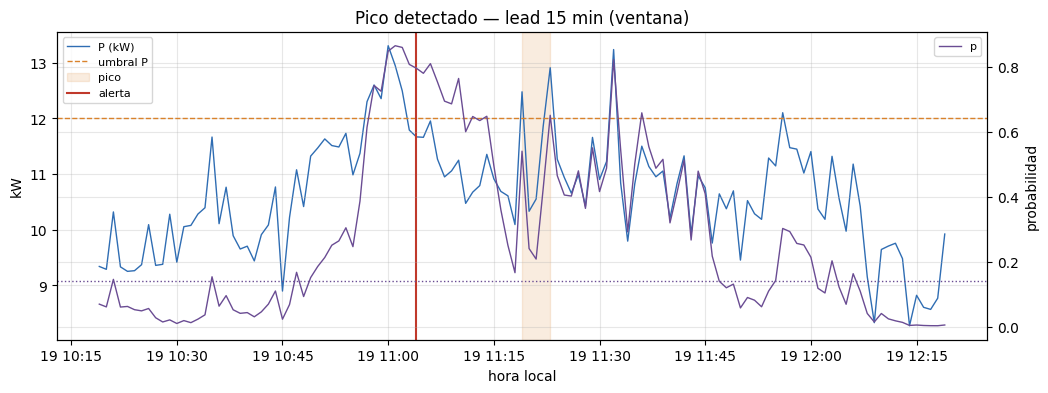

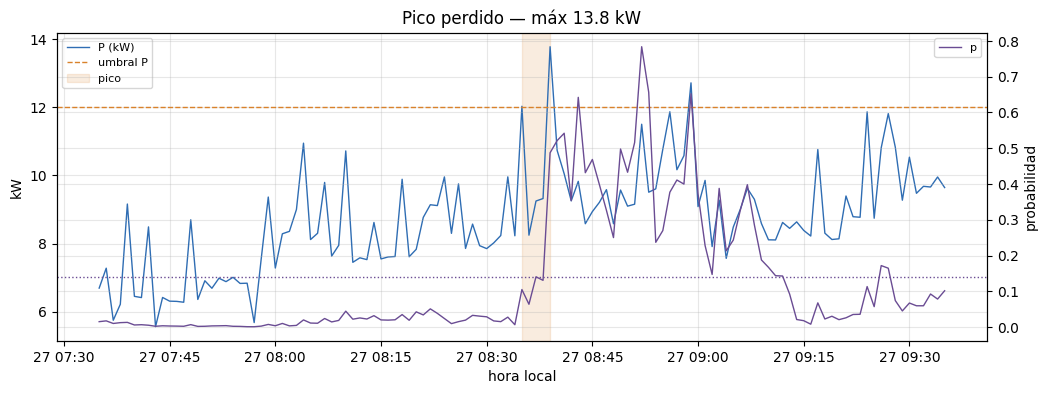

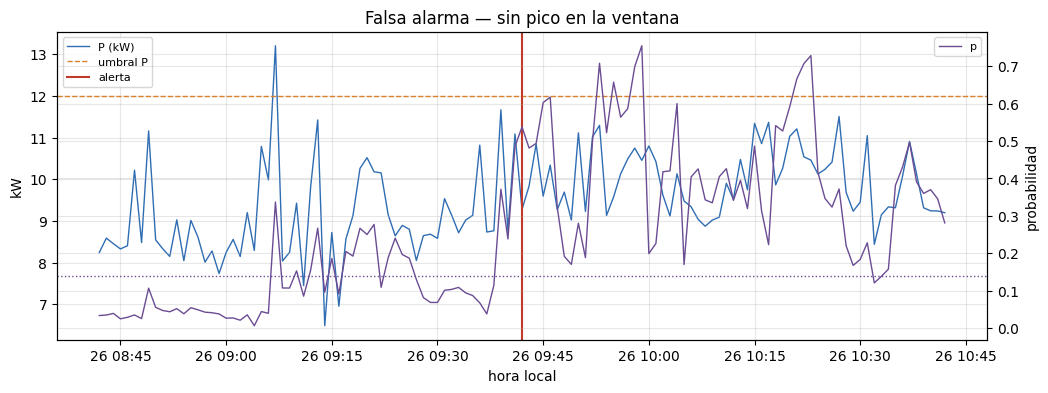

In [10]:
alert_df = pd.DataFrame(alert_rows_op)
alert_df["p_max"] = [oof.loc[a:b, "p_oof"].max() for a, b in zip(alert_df.start, alert_df.end)]
alert_df["P_at_alert"] = [oof.loc[a:b, "P"].max() for a, b in zip(alert_df.start, alert_df.end)]

detected = peak_df[peak_df.detected].sort_values("lead_min", ascending=False)
missed = peak_df[~peak_df.detected].sort_values("max_P", ascending=False)
false_alarm = alert_df[alert_df.type == "FP"].sort_values("p_max", ascending=False)

def plot_case(center, title, fname, peak=None, alert=None):
    t0 = center - pd.Timedelta(hours=1)
    t1 = center + pd.Timedelta(hours=1)
    sub = oof.loc[t0:t1]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(sub.index.tz_convert("America/Bogota"), sub["P"], color="#2f6db3", lw=1, label="P (kW)")
    ax.axhline(P_THR, color="#d9822b", ls="--", lw=1, label="umbral P")
    ax2 = ax.twinx()
    ax2.plot(sub.index.tz_convert("America/Bogota"), sub["p_oof"], color="#6a4c93", lw=1, label="p")
    ax2.axhline(tau_op, color="#6a4c93", ls=":", lw=1)
    ax2.set_ylabel("probabilidad")
    if peak is not None:
        ax.axvspan(peak.start.tz_convert("America/Bogota"), peak.end.tz_convert("America/Bogota"),
                   color="#d9822b", alpha=0.15, label="pico")
    if alert is not None:
        ax.axvline(alert.tz_convert("America/Bogota"), color="#c0392b", ls="-", lw=1.5, label="alerta")
    ax.set_title(title); ax.set_ylabel("kW"); ax.set_xlabel("hora local")
    ax.legend(loc="upper left", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
    fig.savefig(FIG / fname, dpi=150, bbox_inches="tight")
    plt.show()

if len(detected):
    r = detected.iloc[0]
    plot_case(r.start, f"Pico detectado — lead {r.lead_min:.0f} min (ventana)", "03_caso_detectado.png",
              peak=r, alert=r.first_alert)
if len(missed):
    r = missed.iloc[0]
    plot_case(r.start, f"Pico perdido — máx {r.max_P:.1f} kW", "03_caso_perdido.png", peak=r)
if len(false_alarm):
    r = false_alarm.iloc[0]
    plot_case(r.start, "Falsa alarma — sin pico en la ventana", "03_caso_falsa.png", alert=r.start)

## 10. Guardar resultados y resumen

In [11]:
peak_df.to_csv(TAB / "03_picos.csv", index=False)
alert_df.to_csv(TAB / "03_alertas.csv", index=False)
metrics.to_csv(TAB / "03_metricas_umbral.csv", index=False)
cost.to_csv(TAB / "03_costos.csv", index=False)

summary = pd.DataFrame([
    {"punto": "costo_C_FN_10", **m_star},
    {"punto": "operativo_5pct", **m_op},
])
summary = summary[["punto", "threshold", "n_peaks", "detected", "recall",
                   "precision", "fa_per_day", "alert_burden",
                   "lead_median", "lead_p25", "lead_p75"]]
summary.columns = ["punto", "umbral", "n_picos", "picos_detectados",
                   "recall", "precision", "falsas_alarmas_por_dia",
                   "carga_alerta", "lead_mediana_min", "lead_p25_min",
                   "lead_p75_min"]
display(summary.round(3))
summary.to_csv(TAB / "03_resumen.csv", index=False)
print("Guardado en", TAB)

,punto,umbral,n_picos,picos_detectados,recall,precision,falsas_alarmas_por_dia,carga_alerta,lead_mediana_min,lead_p25_min,lead_p75_min
0,costo_C_FN_10,0.002,58,58,1.000,0.260,2.077,0.190,15.0,15.0,15.0
1,operativo_5pct,0.140,58,37,0.638,0.273,2.154,0.053,15.0,8.0,15.0


Guardado en C:\Users\Sebastian Tovar\Documents\Ing.Electronica\VIII\TAM\repo\Proyecto\reports\tables


## 11. Conclusiones

- La evaluación es **retrospectiva**: simula el despliegue sobre los datos disponibles; no reemplaza un piloto prospectivo.
- El modelo se evalúa a nivel de **episodio de pico**, no de minuto; eso evita inflar el recall contando 15 veces el mismo evento.
- El **lead time** y la **carga de alertas** son las métricas que el operador siente; el PR-AUC solo no alcanza.
- La comparación con **persistencia** a igual carga de alertas es el baseline honesto: si el modelo no la supera, no justifica la complejidad.
- La cobertura manda: si los picos perdidos se concentran en días de 30 s o con huecos, el problema es de datos antes que de modelo.
- El umbral se elige por costo, no por F1. Con `C_FN/C_FP = 10`, el punto elegido se reporta en `03_resumen.csv`.

**Limitaciones:** 47 días, 45,3 % de minutos faltantes, un solo medidor confiable, sin armónicos y picos de 10–30 s. La conclusión es un MVP, no una promesa de producción.
